<h1>ScoreLine EDA</h1>
Stage 6 of the pipeline. The goal here is to get a feel for the Premier League data before touching the features again, and to find out where the current 13 features fall short for predicting H/D/A on log loss.
<br><br>
Everything below is on the <b>train split only</b>. Run from <code>ai/training</code>. Testable helpers live in <code>eda.py</code>, this notebook is just plots and reasoning.

In [1]:
import sys, pathlib, glob
sys.path.insert(0, str(pathlib.Path.cwd().parents[1]))  # repo root
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from ai.training import preprocessing as pp, features as F, eda
from ai.training.pipeline import CONFIG

sns.set_theme(style="whitegrid")
FIG_DIR = pathlib.Path("/workspace/eda_figs")  # outside the repo on purpose
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120)

<h1>Dataset Acquisition</h1>
I am using the cached football-data.org pull (<i>PL_2023</i>, <i>PL_2024</i>, <i>PL_2025</i> in <code>data/</code>) rather than hitting the API again, as the free tier is roughly 10 requests a minute and nothing has changed in those seasons.

In [2]:
matches = pd.concat([pd.read_csv(f) for f in sorted(glob.glob("data/PL_*.csv"))]).to_dict("records")
df = pp.load_api_matches(matches)
display(pp.inspect(df))
df = pp.label_result(pp.clean(df))
base = F.build_features(df)
# proposed candidates (eda.candidate_features, prior-only) are joined here so they split with their rows;
# they are only looked at in the last section
cand_cols = list(eda.candidate_features(df, base).columns)
df = df.join(base).join(eda.candidate_features(df, base))
len(df)

{'rows': 1140,
 'nulls': {'id': 0,
  'home_team': 0,
  'away_team': 0,
  'date': 0,
  'status': 0,
  'home_score': 0,
  'away_score': 0},
 'statuses': {'FINISHED': 1140}}

1140

<h1>Create a Test Set</h1>
A potential error here would be to shuffle and split like we would with an unordered dataset. The test set would then be random matches scattered across all three seasons, and the features (form, Elo) of a training match could be computed from results that happen after test matches.
<br><br>
We could then be allowing the model to see the future. Instead the split is chronological (last 20% of matches is test), and the features are built on the full timeline first since they only ever look at <i>prior</i> matches. This is the correct way for time-dependent prediction.
<br><br>
From here on I only look at <code>train_df</code>.

In [3]:
train_df, test_df = pp.time_split(df, CONFIG["test_frac"])
train_df = train_df.assign(
    season=train_df["date"].dt.year - (train_df["date"].dt.month < 8),  # season = start year
    total_goals=train_df["home_score"] + train_df["away_score"],
    goal_diff=train_df["home_score"] - train_df["away_score"],
)
y = train_df["result"]
print(len(train_df), "train", train_df["date"].min().date(), "->", train_df["date"].max().date())
del test_df  # not used anywhere below

912 train 2023-08-11 -> 2025-12-13


<h1>Result Distribution</h1>
First thing to check is the class balance. Log loss is judged against the class prior (the dummy model), so the prior is the bar every model has to beat. I also want to see if home advantage is stable across seasons, as a drifting prior would hurt a model trained on older seasons.

result
H    0.444
A    0.329
D    0.227
Name: proportion, dtype: float64

result,H,D,A
season,,,
2023,0.461,0.216,0.324
2024,0.408,0.245,0.347
2025,0.493,0.211,0.296


season
2023    380
2024    380
2025    152
Name: count, dtype: int64

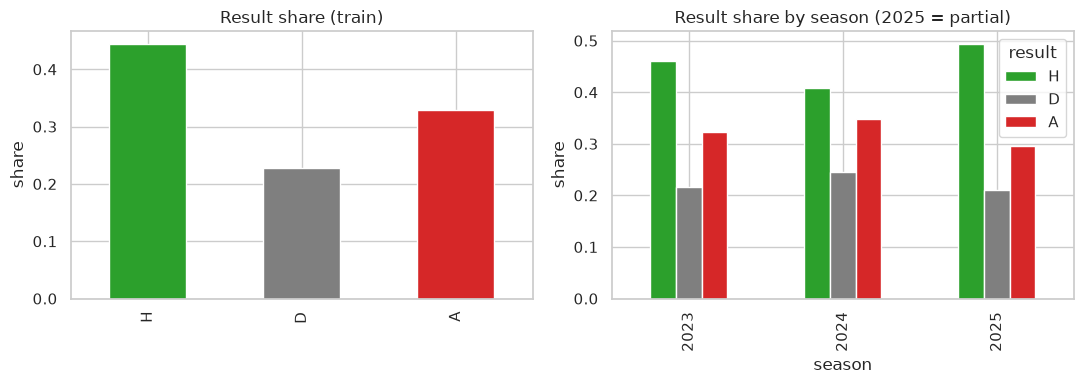

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.value_counts(normalize=True).reindex(eda.RESULTS).plot.bar(ax=axes[0], color=["tab:green", "tab:grey", "tab:red"])
axes[0].set(title="Result share (train)", ylabel="share", xlabel="")
by_season = pd.crosstab(train_df["season"], y, normalize="index")[eda.RESULTS]
by_season.plot.bar(ax=axes[1], color=["tab:green", "tab:grey", "tab:red"])
axes[1].set(title="Result share by season (2025 = partial)", ylabel="share")
save(fig, "01_result_distribution")
display(y.value_counts(normalize=True).round(3), by_season.round(3), train_df["season"].value_counts().sort_index())

<ul>
<li>Over 912 train matches it is 44.4% home wins, 22.7% draws and 32.9% away wins, so home advantage is real but not huge.</li>
<li>Home win share moves around by season: 46.1% (2023/24), 40.8% (2024/25), 49.3% (2025/26, only 152 matches up to 13 Dec 2025). Draws go 21.6% / 24.5% / 21.1%.</li>
<li>Draws are the minority class at under a quarter of matches. A model that never predicts a draw can still have decent accuracy, which is exactly what our random forest does. Log loss is the better judge here as it still rewards a good draw probability even if D is never the argmax.</li>
</ul>

<h1>Goals Distribution</h1>
The result is just the sign of home goals minus away goals, so the goals themselves are worth a look. If goals per side are roughly Poisson, that justifies a Poisson style "expected goals" feature (attack strength x opponent defence), which is the classic football approach. I also want to see which scorelines the draws actually are.

independent Poisson P(draw) = 0.239, observed = 0.227
0-0 observed 0.038 vs Poisson 0.047
1-1 observed 0.106 vs Poisson 0.109


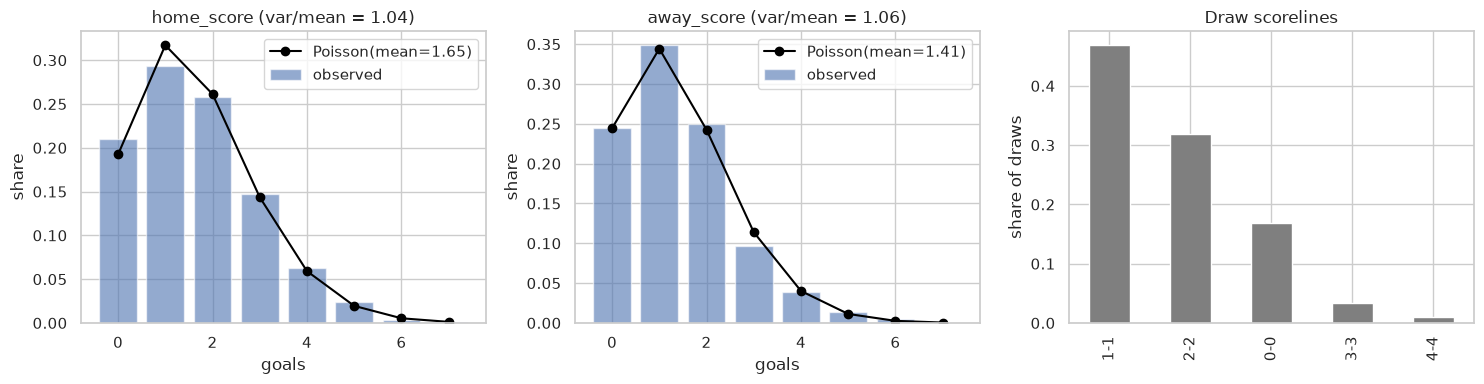

In [5]:
mh, ma = train_df["home_score"].mean(), train_df["away_score"].mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, mu in ((axes[0], "home_score", mh), (axes[1], "away_score", ma)):
    k = np.arange(0, 8)
    obs = train_df[col].value_counts(normalize=True).reindex(k, fill_value=0)
    ax.bar(k, obs, alpha=0.6, label="observed")
    ax.plot(k, stats.poisson.pmf(k, mu), "o-", color="black", label=f"Poisson(mean={mu:.2f})")
    ax.set(title=f"{col} (var/mean = {train_df[col].var() / mu:.2f})", xlabel="goals", ylabel="share")
    ax.legend()
scores = train_df["home_score"].astype(str) + "-" + train_df["away_score"].astype(str)
scores[y == "D"].value_counts(normalize=True).head(5).plot.bar(ax=axes[2], color="tab:grey")
axes[2].set(title="Draw scorelines", ylabel="share of draws")
save(fig, "02_goals_poisson")
p_draw = sum(stats.poisson.pmf(k, mh) * stats.poisson.pmf(k, ma) for k in range(15))
print(f"independent Poisson P(draw) = {p_draw:.3f}, observed = {(y == 'D').mean():.3f}")
print(f"0-0 observed {(scores == '0-0').mean():.3f} vs Poisson {stats.poisson.pmf(0, mh) * stats.poisson.pmf(0, ma):.3f}")
print(f"1-1 observed {(scores == '1-1').mean():.3f} vs Poisson {stats.poisson.pmf(1, mh) * stats.poisson.pmf(1, ma):.3f}")

<ul>
<li>Home teams score 1.65 a game and away teams 1.41 (3.06 total). Variance/mean is 1.04 for home and 1.06 for away, so a plain Poisson fits pretty well, barely any over-dispersion.</li>
<li>Draws are 1-1 (46.9%), 2-2 (31.9%) and 0-0 (16.9%).</li>
<li>Two independent Poissons give P(draw) = 0.239 against 0.227 observed, and 0-0 is actually <i>less</i> common than Poisson says (3.8% vs 4.7%). So there is no big Dixon-Coles style low-score draw inflation in this data, I wouldn't bother with that correction.</li>
<li>Implication: a per-team Poisson expected goals feature is well justified. It won't magically fix draws, but it gives a proper goals-based strength for each side.</li>
</ul>

<h1>Dataset Exploration</h1>
<h2>Feature correlation (Pearson vs Spearman)</h2>
13 features is small enough to plot the whole correlation matrix. Pearson only picks up linear relationships, so I compare with Spearman (rank based) to check nothing is hiding behind outliers, e.g. the capped rest days.

,feature_a,feature_b,r,abs_r
0,home_rest_days,away_rest_days,0.882,0.882
1,home_no_history,away_no_history,0.803,0.803
2,home_ppg,home_gf,0.753,0.753
3,away_ppg,away_gf,0.739,0.739
4,away_ppg,away_ga,-0.634,0.634
5,home_ppg,home_ga,-0.611,0.611
6,h2h_home_ppg,elo_diff,0.512,0.512


largest |Pearson - Spearman|:


home_rest_days     0.103
away_rest_days     0.103
home_ga            0.063
home_no_history    0.063
dtype: float64

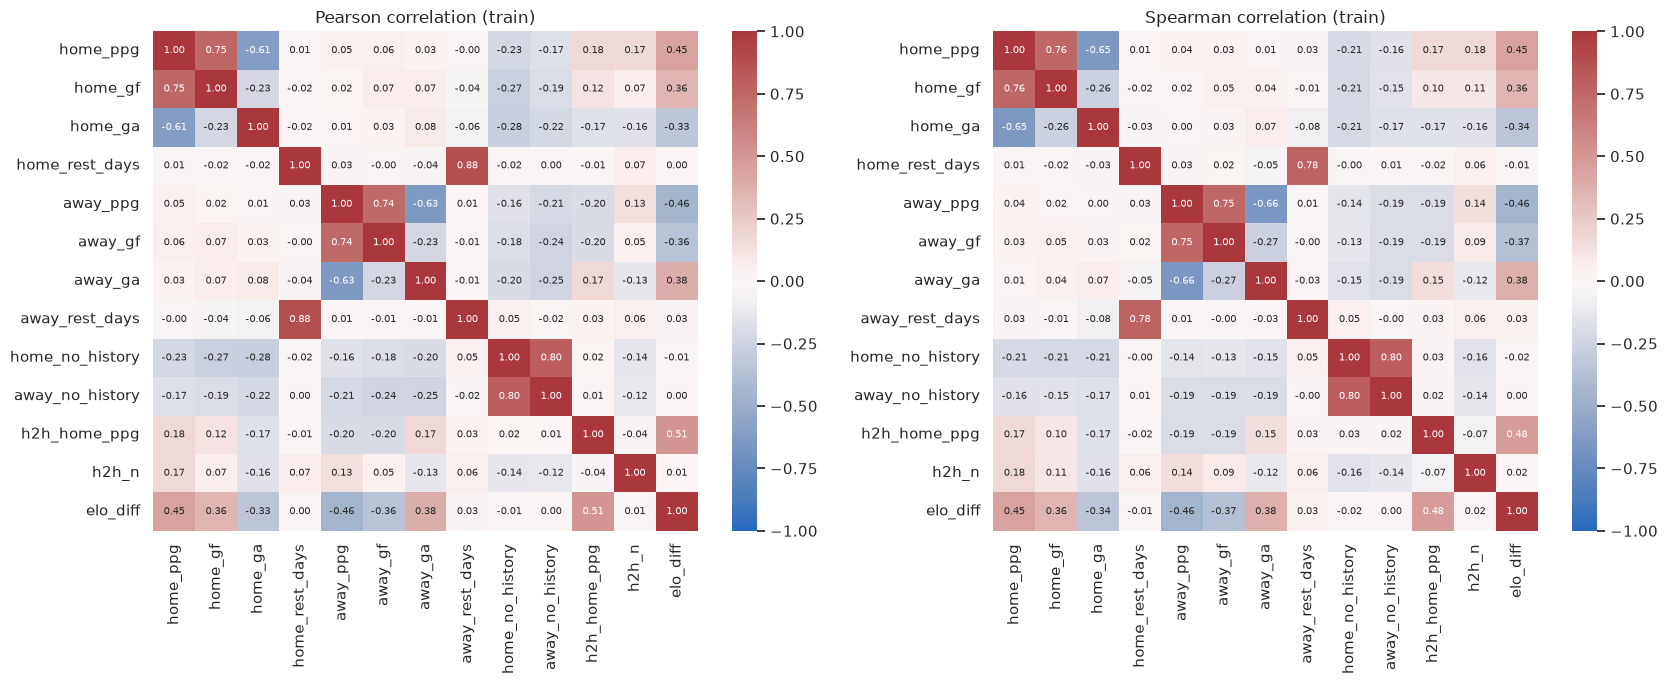

In [6]:
pear = eda.feature_correlation(train_df)
spear = eda.feature_correlation(train_df, method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for ax, corr, name in ((axes[0], pear, "Pearson"), (axes[1], spear, "Spearman")):
    sns.heatmap(corr, ax=ax, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
    ax.set_title(f"{name} correlation (train)")
save(fig, "03_correlation_heatmaps")
display(eda.top_correlated_pairs(pear, threshold=0.5).round(3))
print("largest |Pearson - Spearman|:")
(pear - spear).abs().max().sort_values(ascending=False).head(4).round(3)

<ul>
<li><i>home_rest_days</i> / <i>away_rest_days</i> r = 0.88, both teams share the same fixture calendar, so these are close to redundant with each other.</li>
<li><i>home_no_history</i> / <i>away_no_history</i> r = 0.80, same reason (both flags fire at the very start of the data).</li>
<li><i>ppg</i> with <i>gf</i> is about 0.75 and <i>ppg</i> with <i>ga</i> about -0.62 on each side. Expected, points come from goals, but it means the 8 form features hold less than 8 features of information.</li>
<li><i>h2h_home_ppg</i> vs <i>elo_diff</i> is 0.51, head-to-head is partly just a team strength proxy.</li>
<li>Pearson and Spearman agree within 0.10 everywhere (biggest gap is the rest days at 0.10), so no hidden non-linear monotone relationships between features.</li>
</ul>

<h2>Feature vs target correlation</h2>
Correlation of each feature with a home win indicator, a draw indicator and goal difference. This is what actually matters for the model.

,home_win,draw,goal_diff
home_ppg,0.197,0.020,0.244
home_gf,0.180,0.002,0.221
home_ga,-0.138,-0.016,-0.166
home_rest_days,-0.047,-0.001,-0.064
away_ppg,-0.136,-0.019,-0.165
away_gf,-0.101,-0.057,-0.153
away_ga,0.139,-0.003,0.154
away_rest_days,-0.013,-0.012,-0.029
home_no_history,-0.004,0.018,0.012
away_no_history,0.002,0.012,0.012


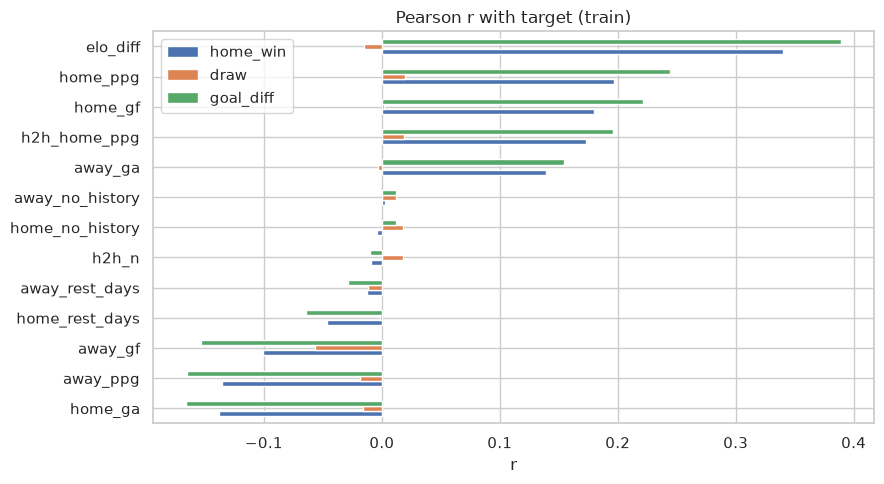

In [7]:
tc = eda.target_correlation(train_df, y, train_df["goal_diff"])
fig, ax = plt.subplots(figsize=(9, 5))
tc.sort_values("goal_diff").plot.barh(ax=ax)
ax.set(title="Pearson r with target (train)", xlabel="r")
save(fig, "04_target_correlation")
tc.round(3)

<ul>
<li><i>elo_diff</i> is the strongest single signal by a distance: r = 0.34 with a home win and 0.39 with goal difference.</li>
<li>Next are <i>home_ppg</i> (0.20 / 0.24), <i>home_gf</i> (0.18 / 0.22) and <i>h2h_home_ppg</i> (0.17 / 0.20).</li>
<li>The draw column is basically flat: the biggest |r| is 0.057 (<i>away_gf</i>). None of the current features tells draws apart, which matches the random forest never predicting a draw.</li>
<li><i>rest_days</i>, <i>no_history</i> and <i>h2h_n</i> are all within |r| 0.06 of zero on every target.</li>
</ul>

<h2>Feature distributions by result</h2>
Correlation is a single number, so I also want to see the full distribution of the main features split by H/D/A. If the D distribution sits right between H and A for every feature, the model has nothing to separate draws on.

,elo_diff,home_ppg,away_ppg,home_gf,away_gf,h2h_home_ppg
result,,,,,,
H,30.236,1.6,1.40,1.6,1.4,1.5
D,2.924,1.4,1.40,1.4,1.4,1.5
A,-46.616,1.0,1.55,1.2,1.6,1.5


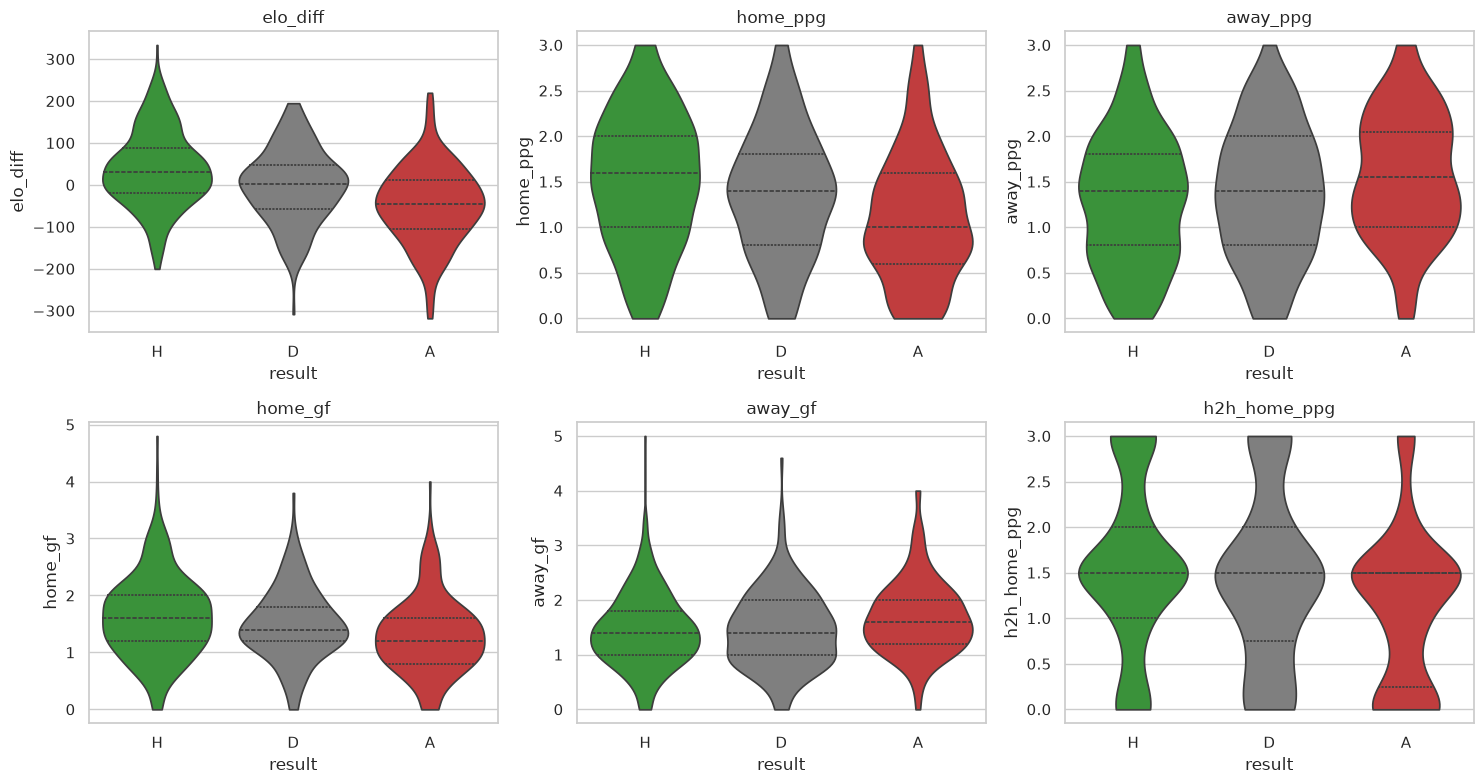

In [8]:
cols = ["elo_diff", "home_ppg", "away_ppg", "home_gf", "away_gf", "h2h_home_ppg"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.violinplot(data=train_df, x="result", y=col, order=eda.RESULTS, ax=ax, cut=0, inner="quartile",
                   hue="result", palette={"H": "tab:green", "D": "tab:grey", "A": "tab:red"}, legend=False)
    ax.set_title(col)
save(fig, "05_features_by_result")
train_df.groupby("result")[cols].median().reindex(eda.RESULTS).round(3)

<ul>
<li><i>elo_diff</i> separates H from A clearly: median 30.2 for home wins, -46.6 for away wins. Draws sit right in the middle at 2.9.</li>
<li><i>home_ppg</i> median is 1.6 (H), 1.4 (D), 1.0 (A). <i>away_ppg</i> goes the other way, 1.4 / 1.4 / 1.55.</li>
<li>For every feature here the draw distribution is just sandwiched between H and A and overlaps heavily with both. So a draw looks like "a close game", which is a <i>non-linear</i> pattern (middle of <i>elo_diff</i>) that a linear model on signed features can't really express. That points to a symmetric feature like |elo_diff|.</li>
</ul>

<h2>Calibration view: empirical P(H/D/A) by elo_diff decile</h2>
Since we're scoring on log loss, what matters is whether the probabilities move smoothly with the strongest feature. This is the "ideal" probability curve a model could learn from <i>elo_diff</i> alone.

result,H,D,A,n
elo_diff,,,,
"(-318.161, -125.332]",0.174,0.217,0.609,92
"(-125.332, -75.322]",0.242,0.220,0.538,91
"(-75.322, -46.045]",0.253,0.242,0.505,91
"(-46.045, -20.902]",0.407,0.220,0.374,91
"(-20.902, 0.0]",0.516,0.194,0.290,93
"(0.0, 20.924]",0.427,0.326,0.247,89
"(20.924, 46.688]",0.473,0.286,0.242,91
"(46.688, 75.009]",0.626,0.121,0.253,91
"(75.009, 133.46]",0.582,0.297,0.121,91


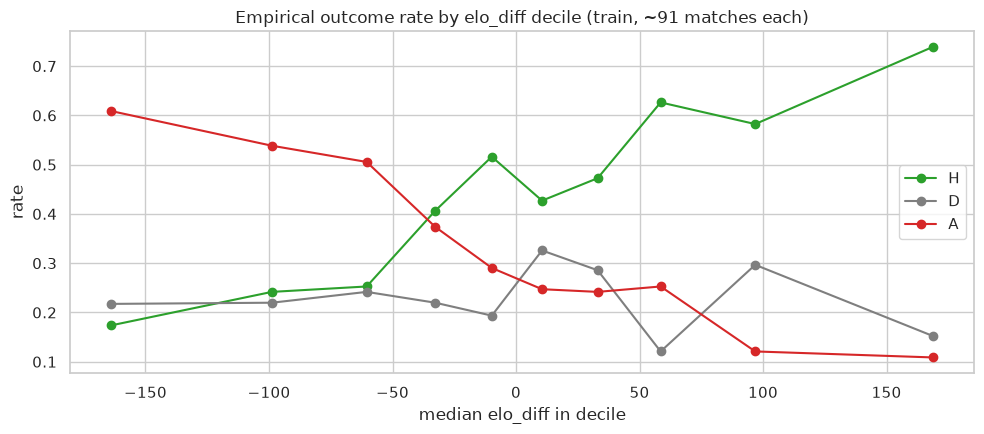

In [9]:
dec = eda.outcome_rates(train_df["elo_diff"], y, 10)
fig, ax = plt.subplots(figsize=(10, 4.5))
mid = train_df.groupby(pd.qcut(train_df["elo_diff"], 10), observed=True)["elo_diff"].median().to_numpy()
for r, c in zip(eda.RESULTS, ["tab:green", "tab:grey", "tab:red"]):
    ax.plot(mid, dec[r], "o-", color=c, label=r)
ax.set(title="Empirical outcome rate by elo_diff decile (train, ~91 matches each)", xlabel="median elo_diff in decile", ylabel="rate")
ax.legend()
save(fig, "06_elo_decile_calibration")
dec.round(3)

<ul>
<li>Home win rate climbs from 17.4% in the lowest decile to 73.9% in the highest, and away wins drop from 60.9% to 10.9%. Nice and close to monotone, so Elo is doing the heavy lifting.</li>
<li>The draw rate bounces between 12.1% and 32.6% with no clean shape. The two deciles either side of zero are 19.4% and 32.6%, then 28.6%, then 12.1%. With ~91 matches per bin the noise is roughly ±4 points, so this is mostly noise.</li>
<li>The (-20.9, 0] decile has an odd 51.6% home win rate. That bin contains all the <i>elo_diff</i> = 0 matches at the start of the data (and promoted teams starting at 1500), so it isn't a real effect, more a sign that Elo needs a few matches to warm up.</li>
</ul>

<h1>Draw Analysis</h1>
Draws are the weak spot, so I look at three ideas for what makes a draw more likely:
<ul>
<li>closeness of the teams, |elo_diff|</li>
<li>low scoring sides, using the combined recent goals for (<i>home_gf + away_gf</i>)</li>
<li>season stage, e.g. more cagey games late in the season</li>
</ul>

result,H,D,A,n
elo_diff,,,,
"(-1, 50]",0.452,0.254,0.293,389
"(50, 100]",0.441,0.203,0.355,256
"(100, 150]",0.403,0.266,0.331,139
"(150, 400]",0.469,0.148,0.383,128


result,H,D,A,n
row_0,,,,
"(-0.001, 2.2]",0.437,0.237,0.326,215
"(2.2, 2.8]",0.383,0.228,0.388,206
"(2.8, 3.2]",0.462,0.234,0.304,158
"(3.2, 3.8]",0.445,0.232,0.323,155
"(3.8, 8.0]",0.506,0.202,0.292,178


result,H,D,A,n
Aug-Oct,0.446,0.232,0.321,280
Nov-Dec,0.469,0.215,0.316,256
Jan-Feb,0.379,0.214,0.407,145
Mar-May,0.455,0.242,0.303,231


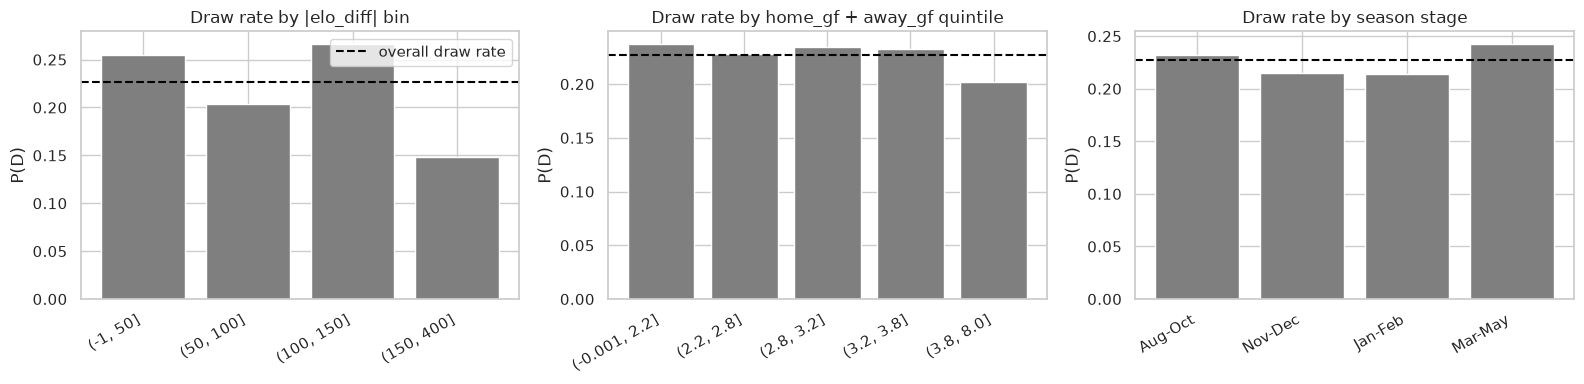

In [10]:
close = eda.outcome_rates(train_df["elo_diff"].abs(), y, [-1, 50, 100, 150, 400])
low = eda.outcome_rates(train_df["home_gf"] + train_df["away_gf"], y, 5)
month = (train_df["date"].dt.month - 8) % 12  # 0 = August
stage = eda.outcome_rates(month, y, [-1, 2, 4, 6, 10])
stage.index = ["Aug-Oct", "Nov-Dec", "Jan-Feb", "Mar-May"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, tab, title in ((axes[0], close, "|elo_diff| bin"), (axes[1], low, "home_gf + away_gf quintile"), (axes[2], stage, "season stage")):
    ax.bar(range(len(tab)), tab["D"], color="tab:grey")
    ax.axhline((y == "D").mean(), color="black", ls="--", label="overall draw rate")
    ax.set_xticks(range(len(tab)), [str(i) for i in tab.index], rotation=30, ha="right")
    ax.set(title=f"Draw rate by {title}", ylabel="P(D)")
axes[0].legend()
save(fig, "07_draw_analysis")
display(close.round(3), low.round(3), stage.round(3))

<ul>
<li><b>Closeness:</b> |elo_diff| <= 50 has a 25.4% draw rate (389 matches) against 14.8% when |elo_diff| > 150 (128 matches). That's the clearest draw signal I've found, although the 100-150 bin (26.6%) breaks the trend so it is not perfectly monotone.</li>
<li><b>Low scoring form:</b> the quintile with the lowest combined recent gf has 23.7% draws vs 20.2% in the highest. Small, and the middle quintiles are flat around 23%, so recent goals on their own don't say much about draws.</li>
<li><b>Season stage:</b> 23.2% (Aug-Oct), 21.5% (Nov-Dec), 21.4% (Jan-Feb), 24.2% (Mar-May). Basically flat, I wouldn't add season stage for draws.</li>
<li>Implication: |elo_diff| is worth adding as its own feature. Tree models can find the middle of <i>elo_diff</i> themselves, but logreg and the MoE experts can't without it.</li>
</ul>

<h1>Temporal Drift</h1>
The model is trained on older seasons and tested on the most recent matches, so if the game itself drifts (fewer goals, less home advantage) the test set looks different from train. Checking by season and with a rolling window.

,home_score,away_score,total_goals
season,,,
2023,1.800,1.479,3.279
2024,1.513,1.421,2.934
2025,1.605,1.204,2.809


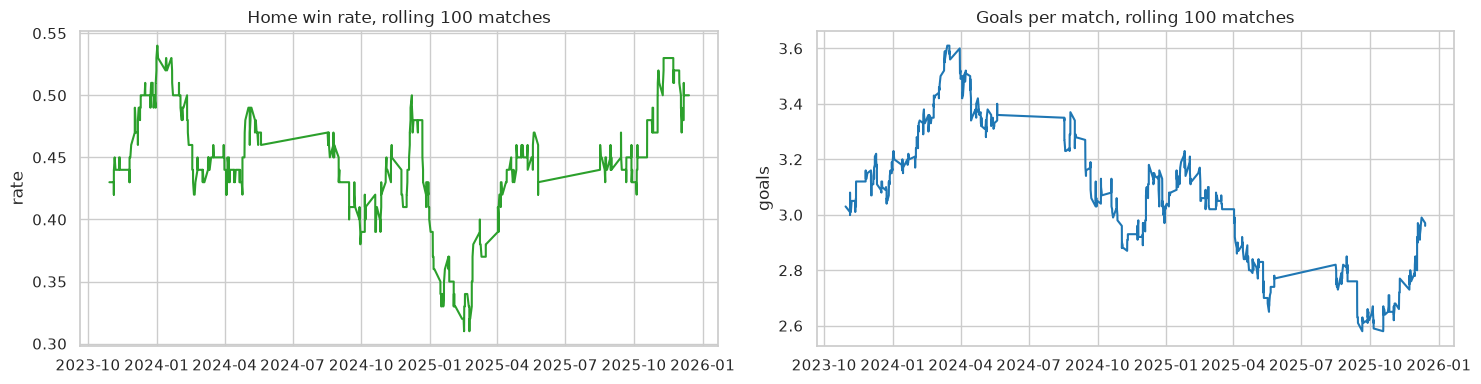

In [11]:
ordered = train_df.sort_values("date")
roll = ordered[["total_goals"]].assign(home_win=(ordered["result"] == "H").astype(float)).rolling(100).mean()
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(ordered["date"], roll["home_win"], color="tab:green")
axes[0].set(title="Home win rate, rolling 100 matches", ylabel="rate")
axes[1].plot(ordered["date"], roll["total_goals"], color="tab:blue")
axes[1].set(title="Goals per match, rolling 100 matches", ylabel="goals")
save(fig, "08_temporal_drift")
train_df.groupby("season")[["home_score", "away_score", "total_goals"]].mean().round(3)

<ul>
<li>Goals per match drop each season: 3.28 (2023/24), 2.93 (2024/25), 2.81 (2025/26 so far). Away goals go 1.48 / 1.42 / 1.20.</li>
<li>Home win share isn't trending one way, 46.1% -> 40.8% -> 49.3%, but it does swing.</li>
<li>Implication: anything goals based should be <i>relative to recent league averages</i> rather than absolute counts, otherwise a 2023 "high scoring" side and a 2025 one aren't comparable. The expected goals feature below uses the prior league average for exactly this reason. Elo already handles drift as it is relative.</li>
</ul>

<h1>Rest Days &amp; No History</h1>
These four features came in on the first pass, so I want to check if they carry their weight.

result,H,D,A,n
row_0,,,,
"(-15.0, -1.5]",0.525,0.197,0.279,61
"(-1.5, 1.5]",0.439,0.229,0.331,785
"(1.5, 15.0]",0.424,0.227,0.348,66


no_history rows: home 14 away 11 of 912


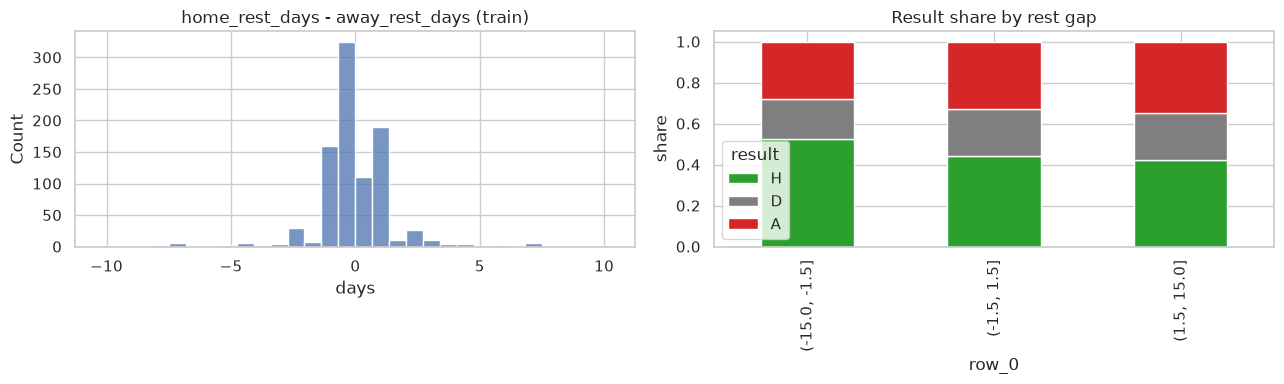

In [12]:
rest_gap = train_df["home_rest_days"] - train_df["away_rest_days"]
rest = eda.outcome_rates(rest_gap, y, [-15, -1.5, 1.5, 15])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(rest_gap, bins=30, ax=axes[0])
axes[0].set(title="home_rest_days - away_rest_days (train)", xlabel="days")
rest[eda.RESULTS].plot.bar(stacked=True, ax=axes[1], color=["tab:green", "tab:grey", "tab:red"])
axes[1].set(title="Result share by rest gap", ylabel="share")
save(fig, "09_rest_days")
display(rest.round(3))
print("no_history rows: home", int(train_df["home_no_history"].sum()), "away", int(train_df["away_no_history"].sum()), "of", len(train_df))

<ul>
<li><i>home_rest_days</i> / <i>away_rest_days</i>: 785 of 912 matches (86%) have a rest gap within ±1.5 days. In the other two bins (61 and 66 matches) the result shares move by a few points in a direction that doesn't make sense (the more rested home side wins <i>less</i>), so it's noise. Can be dropped, or at most merged into one <i>rest_gap</i>.</li>
<li><i>home_no_history</i> / <i>away_no_history</i>: only 14 and 11 matches have the flag set, all at the very start of the data. Can be dropped, as they are only telling the model "this is the first gameweek of 2023/24". Correlated 0.80 with each other too.</li>
<li><i>h2h_n</i>: r with every target is under 0.02. It's just "how many times have these teams met in our data", redundant and can be dropped.</li>
</ul>

<h2>Collinearity (VIF)</h2>
VIF = how much a feature's coefficient variance is inflated by the other features. Above ~5 means the feature is mostly explained by the rest. Matters for logreg and the MoE experts more than the trees.

home_ppg           5.51
away_ppg           5.47
away_rest_days     5.10
home_rest_days     5.03
home_no_history    3.69
away_no_history    3.52
home_gf            2.97
away_ga            2.94
away_gf            2.92
home_ga            2.85
elo_diff           2.28
h2h_home_ppg       1.39
h2h_n              1.11
Name: vif, dtype: float64

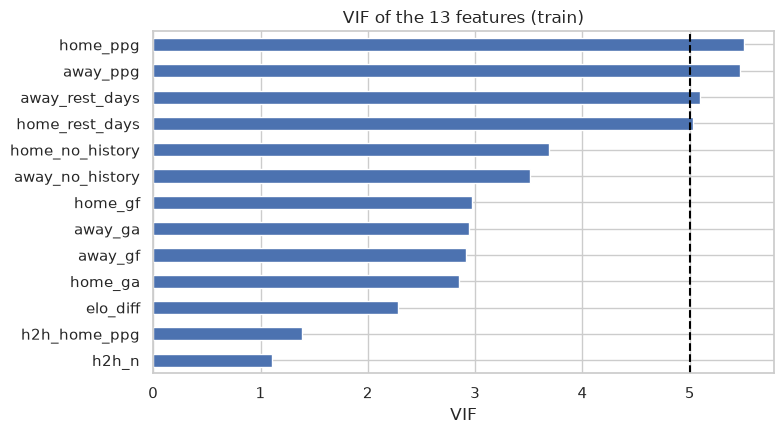

In [13]:
v = eda.vif(train_df)
fig, ax = plt.subplots(figsize=(8, 4.5))
v.sort_values().plot.barh(ax=ax)
ax.axvline(5, color="black", ls="--")
ax.set(title="VIF of the 13 features (train)", xlabel="VIF")
save(fig, "10_vif")
v.round(2)

<ul>
<li><i>home_ppg</i> (5.51), <i>away_ppg</i> (5.47), <i>away_rest_days</i> (5.10) and <i>home_rest_days</i> (5.03) are all above 5.</li>
<li>The <i>gf</i>/<i>ga</i> features sit around 2.9, <i>elo_diff</i> 2.28.</li>
<li>Implication: the form block is redundant with itself. A single home-minus-away form difference would carry most of the same information with far less collinearity, which helps logreg.</li>
</ul>

<h1>Proposed New Features</h1>
Based on the above, these are the candidates I'm proposing. They are computed in <code>eda.candidate_features</code> for exploration only. They are <b>not</b> in <code>FEATURE_COLUMNS</code> and <code>train.py</code> doesn't use them. No CV or test evaluation yet, that waits for a go-ahead.
<br><br>
All of them are leakage safe in the same way as <code>features.py</code>: every per-team stat is <code>shift(1)</code>-ed before the <code>ewm</code>/<code>rolling</code>, and the league averages are shifted expanding means, so a match's own score never feeds into its own features.
<ul>
<li><i>abs_elo_diff</i> = |elo_diff|. Closeness of the teams, for draws.</li>
<li><i>ewm_gd_diff</i> = home team's exponentially weighted goal difference over prior matches (span 10) minus the away team's. One form feature instead of 8 collinear ones, and it weights recent games more without a hard 5 game cutoff.</li>
<li><i>exp_home_goals</i>, <i>exp_away_goals</i>, <i>exp_total_goals</i>: Poisson style. exp_home_goals = league prior avg home goals x (home ewm gf / league avg) x (away ewm ga / league avg), same for away, total is the sum. Relative to the league average so it copes with the goals drift.</li>
<li><i>home_venue_ppg</i> / <i>away_venue_ppg</i>: home team's ppg in its last 5 <i>home</i> games, away team's in its last 5 <i>away</i> games.</li>
</ul>

In [14]:
tdf = train_df  # candidates were built on the full timeline (prior-only) and split with their rows
cand = tdf[cand_cols]
targets = {"home_win": (y == "H").astype(float), "draw": (y == "D").astype(float),
           "goal_diff": tdf["goal_diff"], "total_goals": tdf["total_goals"]}
cand_corr = pd.DataFrame({k: cand.corrwith(t) for k, t in targets.items()})
ref = pd.DataFrame({k: tdf[["elo_diff", "home_ppg", "home_gf", "away_gf"]].corrwith(t) for k, t in targets.items()})
display(pd.concat([cand_corr, ref], keys=["candidate", "current"]).round(3))
print("nulls in candidates:", int(cand.isna().sum().sum()))
tdf[["ewm_gd_diff", "elo_diff", "exp_home_goals", "home_gf", "home_venue_ppg", "home_ppg"]].corr().round(2)

home_win   draw  goal_diff  total_goals
candidate abs_elo_diff       -0.007 -0.062     -0.059        0.028
          elo_exp_home        0.339 -0.010      0.394        0.013
          ewm_gd_diff         0.287  0.033      0.355       -0.004
          home_venue_ppg      0.198  0.030      0.257        0.029
          away_venue_ppg     -0.104  0.024     -0.109       -0.009
          exp_home_goals      0.249 -0.006      0.294        0.047
          exp_away_goals     -0.218 -0.042     -0.279        0.044
          exp_total_goals     0.060 -0.039      0.054        0.080
current   elo_diff            0.340 -0.015      0.389        0.016
          home_ppg            0.197  0.020      0.244        0.005
          home_gf             0.180  0.002      0.221        0.030
          away_gf            -0.101 -0.057     -0.153        0.047

nulls in candidates: 0


,ewm_gd_diff,elo_diff,exp_home_goals,home_gf,home_venue_ppg,home_ppg
ewm_gd_diff,1.00,0.74,0.80,0.52,0.46,0.57
elo_diff,0.74,1.00,0.60,0.36,0.46,0.45
exp_home_goals,0.80,0.60,1.00,0.65,0.42,0.48
home_gf,0.52,0.36,0.65,1.00,0.51,0.75
home_venue_ppg,0.46,0.46,0.42,0.51,1.00,0.65
home_ppg,0.57,0.45,0.48,0.75,0.65,1.00


result,H,D,A,n
row_0,,,,
"(-5.1450000000000005, -0.759]",0.208,0.186,0.607,183
"(-0.759, -0.0572]",0.434,0.220,0.346,182
"(-0.0572, 0.411]",0.401,0.275,0.324,182
"(0.411, 1.144]",0.533,0.231,0.236,182
"(1.144, 5.666]",0.645,0.224,0.131,183


result,H,D,A,n
exp_total_goals,,,,
"(0.0, 2.5]",0.411,0.249,0.340,297
"(2.5, 3.0]",0.458,0.187,0.356,225
"(3.0, 3.5]",0.437,0.270,0.293,174
"(3.5, 10.0]",0.481,0.204,0.315,216


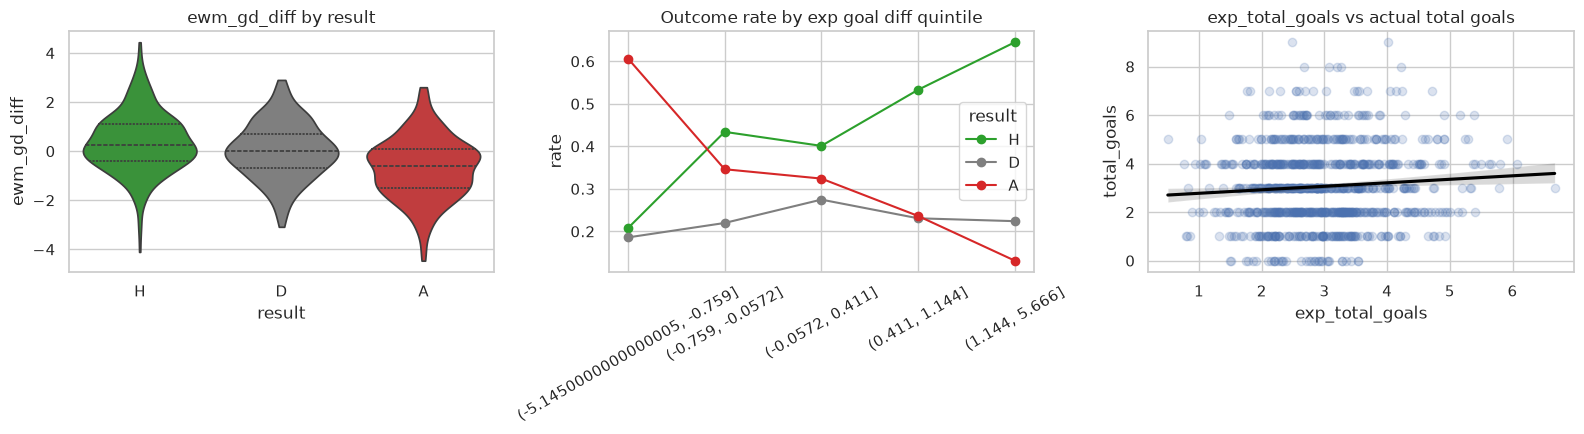

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.violinplot(data=tdf, x="result", y="ewm_gd_diff", order=eda.RESULTS, ax=axes[0], cut=0, inner="quartile",
               hue="result", palette={"H": "tab:green", "D": "tab:grey", "A": "tab:red"}, legend=False)
axes[0].set_title("ewm_gd_diff by result")
xg = eda.outcome_rates(tdf["exp_home_goals"] - tdf["exp_away_goals"], y, 5)
xg[eda.RESULTS].plot(ax=axes[1], marker="o", color=["tab:green", "tab:grey", "tab:red"])
axes[1].set(title="Outcome rate by exp goal diff quintile", ylabel="rate", xlabel="")
axes[1].tick_params(axis="x", rotation=30)
sns.regplot(data=tdf, x="exp_total_goals", y="total_goals", ax=axes[2], scatter_kws={"alpha": 0.2}, line_kws={"color": "black"})
axes[2].set(title="exp_total_goals vs actual total goals")
save(fig, "11_candidate_features")
display(xg.round(3), eda.outcome_rates(tdf["exp_total_goals"], y, [0, 2.5, 3.0, 3.5, 10]).round(3))

<h3>What the candidates show (train only)</h3>
<ul>
<li><i>ewm_gd_diff</i>: r = 0.29 with a home win and 0.36 with goal difference. That's better than any single current form feature (best was <i>home_ppg</i> at 0.20 / 0.24), and it's one feature instead of eight. Medians are -0.60 (A), 0.00 (D), 0.24 (H). It is correlated 0.74 with <i>elo_diff</i> though, so some of it is the same team strength info. Worth trying, maybe as a replacement for the 8 rolling form columns rather than on top of them.</li>
<li><i>exp_home_goals</i> / <i>exp_away_goals</i>: r = 0.29 and -0.28 with goal difference, about as strong as <i>ewm_gd_diff</i>. Split into quintiles of exp_home_goals - exp_away_goals, home wins go 20.8% -> 64.5% and away wins 60.7% -> 13.1%, a clean monotone curve. <i>exp_total_goals</i> has r = 0.08 with actual total goals, weak, but higher than any current gf/ga feature (all under 0.05). Draw r is only -0.04. Lowest exp_total band (<= 2.5) has 24.9% draws vs 20.4% in the highest (> 3.5), but the 3.0-3.5 band is 27.0%, so no clean draw trend. Useful mainly as a strength feature and for an over/under target later.</li>
<li><i>abs_elo_diff</i>: draw r = -0.062, the largest draw correlation so far (just ahead of <i>away_gf</i> at -0.057), and the 25.4% vs 14.8% draw rate gap from the draw analysis. Weak but it is the only feature aimed at draws.</li>
<li><i>home_venue_ppg</i>: r = 0.20 / 0.26, only a hair above <i>home_ppg</i> (0.20 / 0.24) and correlated 0.65 with it. <i>away_venue_ppg</i> is weaker (-0.10 / -0.11). Lowest priority, the venue split halves the sample per team so it's noisier.</li>
</ul>
<h3>Proposal</h3>
<ol>
<li>Add <i>abs_elo_diff</i> (draw signal).</li>
<li>Add <i>ewm_gd_diff</i>, and test it as a replacement for the 8 rolling form features.</li>
<li>Add <i>exp_home_goals</i>, <i>exp_away_goals</i>, <i>exp_total_goals</i>.</li>
<li>Optional: <i>home_venue_ppg</i> / <i>away_venue_ppg</i>.</li>
<li>Drop <i>home_rest_days</i>, <i>away_rest_days</i>, <i>home_no_history</i>, <i>away_no_history</i> and <i>h2h_n</i> (see above).</li>
</ol>
None of this proves a lower log loss yet. Next step (once agreed) is the same TimeSeriesSplit CV as <code>select_model</code> on train, adding one group at a time, and only keeping groups that lower CV log loss. Test set only once at the very end.